In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set chart style
sns.set_theme(style="whitegrid", palette="viridis")

# Create figures directory
os.makedirs("reports/figures", exist_ok=True)

print("Setup completed successfully!")

Setup completed successfully!


In [2]:
df = pd.read_csv("dataset.csv")

# Display first five rows
df.head()

,Date,Category,Sales,Profit,Quantity
0,2026-01-01,Electronics,12000,3000,5
1,2026-01-05,Furniture,8000,1500,4
2,2026-01-10,Clothing,5000,1200,10
3,2026-01-15,Electronics,15000,4500,6
4,2026-01-20,Furniture,9000,2000,5


In [3]:
print(df.shape)
print(df.info())
print(df.describe())

(30, 5)
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      30 non-null     str  
 1   Category  30 non-null     str  
 2   Sales     30 non-null     int64
 3   Profit    30 non-null     int64
 4   Quantity  30 non-null     int64
dtypes: int64(3), str(2)
memory usage: 1.3 KB
None
              Sales        Profit   Quantity
count     30.000000     30.000000  30.000000
mean   15633.333333   4453.333333  12.866667
std     7862.978875   2934.425084   6.224165
min     5000.000000   1200.000000   4.000000
25%    10250.000000   2500.000000   8.250000
50%    13500.000000   3400.000000  12.000000
75%    18750.000000   5325.000000  16.000000
max    35000.000000  12000.000000  27.000000


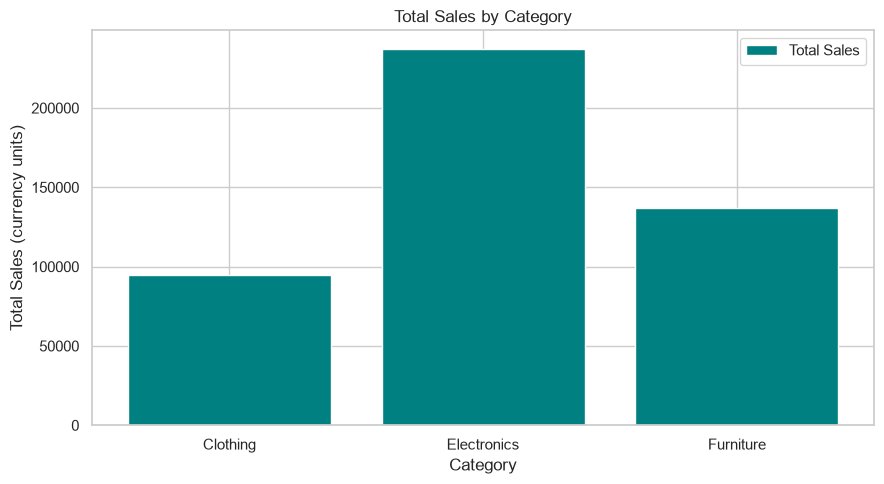

In [4]:
plt.figure(figsize=(9, 5))

category_sales = df.groupby("Category")["Sales"].sum()

plt.bar(
    category_sales.index,
    category_sales.values,
    color="teal",
    label="Total Sales"
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales (currency units)")
plt.legend()

plt.tight_layout()

plt.savefig("reports/figures/01_bar_chart.png", dpi=300)
plt.show()

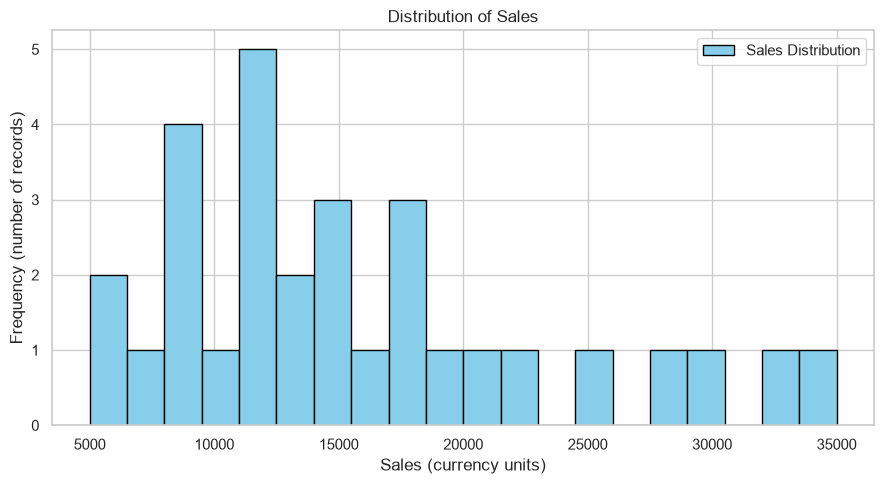

In [5]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Sales"].dropna(),
    bins=20,
    color="skyblue",
    edgecolor="black",
    label="Sales Distribution"
)

plt.title("Distribution of Sales")
plt.xlabel("Sales (currency units)")
plt.ylabel("Frequency (number of records)")
plt.legend()

plt.tight_layout()

plt.savefig("reports/figures/02_histogram.png", dpi=300)
plt.show()


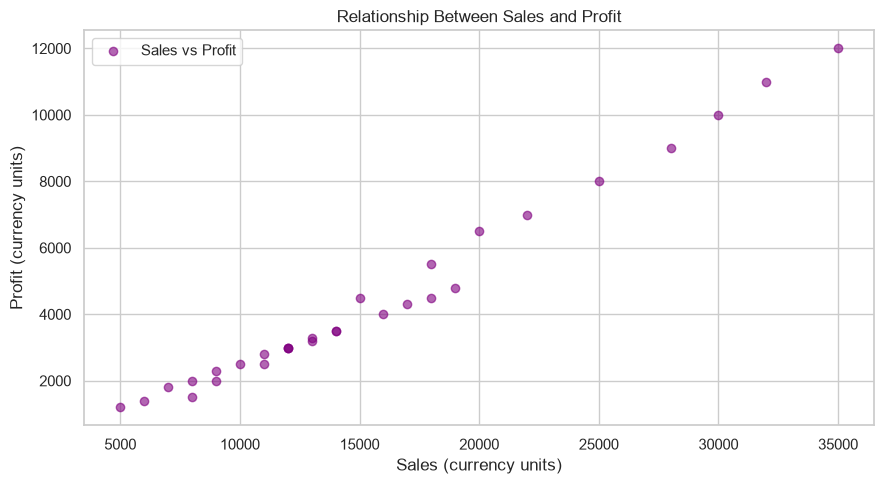

In [6]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Sales"],
    df["Profit"],
    color="purple",
    alpha=0.6,
    label="Sales vs Profit"
)

plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales (currency units)")
plt.ylabel("Profit (currency units)")
plt.legend()

plt.tight_layout()

plt.savefig("reports/figures/03_scatter_plot.png", dpi=300)
plt.show()

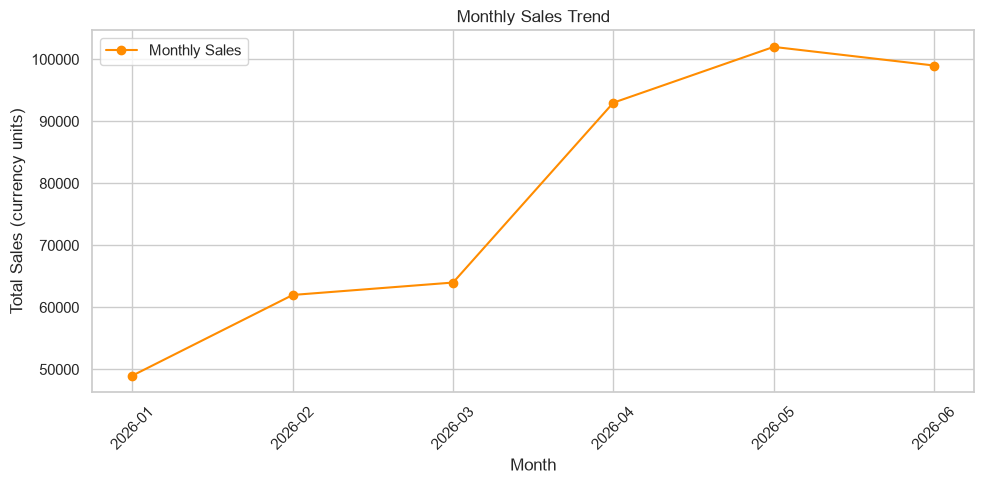

In [7]:
df["Date"] = pd.to_datetime(df["Date"])

monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Sales"]
    .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    color="darkorange",
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (currency units)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()

plt.savefig("reports/figures/04_line_chart.png", dpi=300)
plt.show()

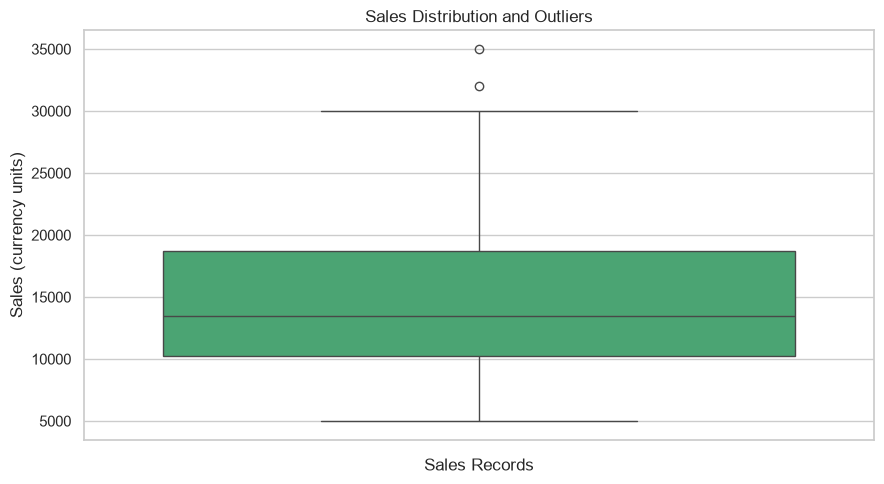

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    y=df["Sales"],
    color="mediumseagreen"
)

plt.title("Sales Distribution and Outliers")
plt.xlabel("Sales Records")
plt.ylabel("Sales (currency units)")

plt.tight_layout()

plt.savefig("reports/figures/05_box_plot.png", dpi=300)
plt.show()

In [9]:
print(os.listdir("reports/figures"))

['01_bar_chart.png', '02_histogram.png', '03_scatter_plot.png', '04_line_chart.png', '05_box_plot.png']
